# Import Library & Membaca Dataset

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error, r2_score
)

FILE_PATH = "02_diabetes.csv"
df = pd.read_csv(FILE_PATH)

print("Ukuran dataset:", df.shape)
display(df.head())
#202431124_Abhillasitta

Ukuran dataset: (100000, 9)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


# EDA

In [8]:
# Struktur, tipe data, dan statistik deskriptif
df.info()
display(df.describe(include="all").T)

# Missing values dan duplikasi
print("Missing values per kolom:")
display(df.isnull().sum().to_frame("Jumlah Missing Values"))

print("Jumlah baris duplikat:", df.duplicated().sum())

# Distribusi target
print("Distribusi target:")
display(df["diabetes"].value_counts().rename(index={0:"Tidak diabetes", 1:"Diabetes"}))
display((df["diabetes"].value_counts(normalize=True)*100).round(2))
#202431124_Abhillasitta

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
gender,100000,3,Female,58552,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,100000.0,NaN,NaN,NaN,41.885856,22.51684,0.08,24.0,43.0,60.0,80.0
hypertension,100000.0,NaN,NaN,NaN,0.07485,0.26315,0.0,0.0,0.0,0.0,1.0
heart_disease,100000.0,NaN,NaN,NaN,0.03942,0.194593,0.0,0.0,0.0,0.0,1.0
smoking_history,100000,6,No Info,35816,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,100000.0,NaN,NaN,NaN,27.320767,6.636783,10.01,23.63,27.32,29.58,95.69
HbA1c_level,100000.0,NaN,NaN,NaN,5.527507,1.070672,3.5,4.8,5.8,6.2,9.0
blood_glucose_level,100000.0,NaN,NaN,NaN,138.05806,40.708136,80.0,100.0,140.0,159.0,300.0
diabetes,100000.0,NaN,NaN,NaN,0.085,0.278883,0.0,0.0,0.0,0.0,1.0


Missing values per kolom:


,Jumlah Missing Values
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


Jumlah baris duplikat: 3854
Distribusi target:


Tidak diabetes    91500
Diabetes           8500
Name: diabetes, dtype: int64

0    91.5
1     8.5
Name: diabetes, dtype: float64

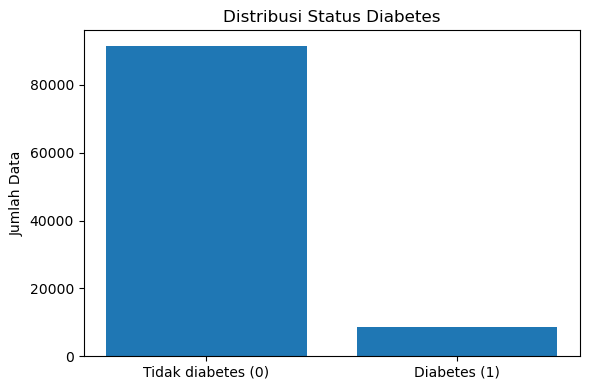

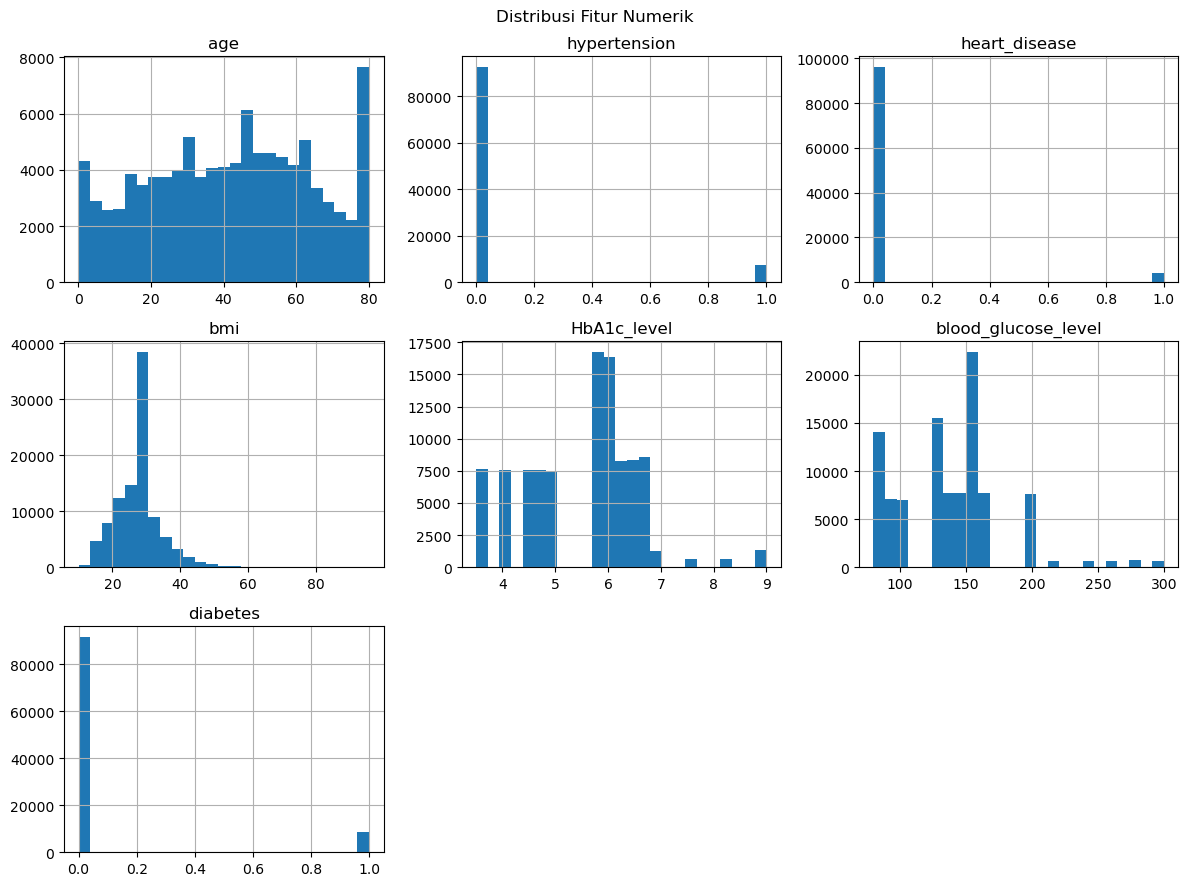

In [9]:
# Visualisasi distribusi target
target_counts = df["diabetes"].value_counts().sort_index()
plt.figure(figsize=(6,4))
plt.bar(["Tidak diabetes (0)", "Diabetes (1)"], target_counts.values)
plt.title("Distribusi Status Diabetes")
plt.ylabel("Jumlah Data")
plt.tight_layout()
plt.show()

# Histogram fitur numerik
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
df[numeric_cols].hist(figsize=(12,9), bins=25)
plt.suptitle("Distribusi Fitur Numerik")
plt.tight_layout()
plt.show()
#202431124_Abhillasitta

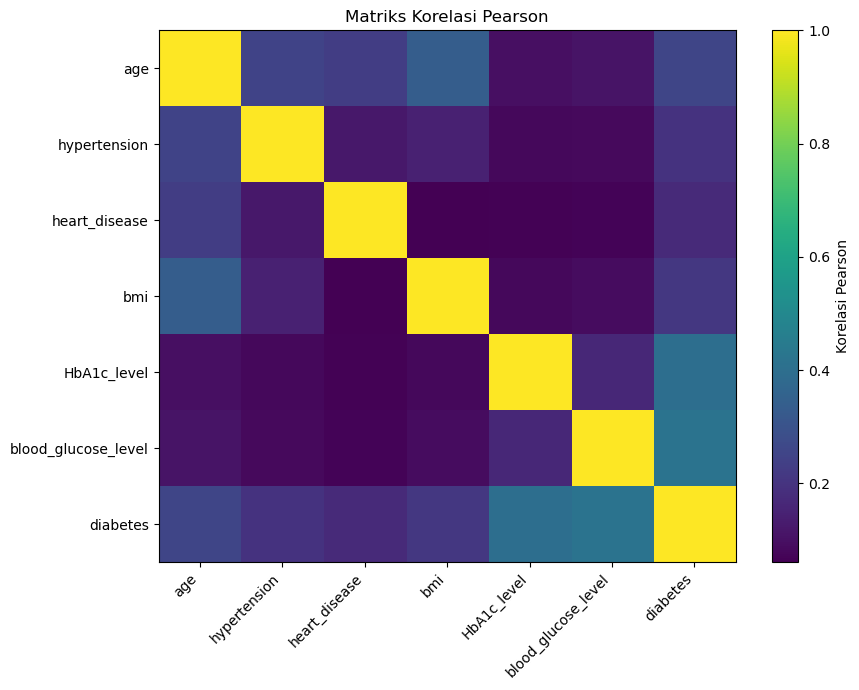

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
age,1.000,0.251,0.233,0.337,0.101,0.111,0.258
hypertension,0.251,1.000,0.121,0.148,0.081,0.084,0.198
heart_disease,0.233,0.121,1.000,0.061,0.068,0.070,0.172
bmi,0.337,0.148,0.061,1.000,0.083,0.091,0.214
HbA1c_level,0.101,0.081,0.068,0.083,1.000,0.167,0.401
blood_glucose_level,0.111,0.084,0.070,0.091,0.167,1.000,0.420
diabetes,0.258,0.198,0.172,0.214,0.401,0.420,1.000


In [10]:
# Korelasi Pearson antarfitur numerik
corr = df[numeric_cols].corr(method="pearson")
plt.figure(figsize=(9,7))
plt.imshow(corr, aspect="auto")
plt.colorbar(label="Korelasi Pearson")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr.index)), corr.index)
plt.title("Matriks Korelasi Pearson")
plt.tight_layout()
plt.show()
display(corr.round(3))
#202431124_Abhillasitta

# Preprocessing Data

In [11]:
# Hapus baris duplikat
data = df.drop_duplicates().copy()
print("Ukuran sebelum menghapus duplikat:", df.shape)
print("Ukuran setelah menghapus duplikat:", data.shape)
print("Duplikat tersisa:", data.duplicated().sum())

# Pisahkan fitur dan target klasifikasi
X = data.drop(columns="diabetes")
y = data["diabetes"]

# Identifikasi kolom kategorikal dan numerik
cat_cols = X.select_dtypes(include="object").columns.tolist()
num_cols = X.select_dtypes(exclude="object").columns.tolist()

print("Kolom kategorikal:", cat_cols)
print("Kolom numerik:", num_cols)

# Split stratified: 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Data latih:", X_train.shape)
print("Data uji:", X_test.shape)
print("Proporsi target data uji:")
display(y_test.value_counts(normalize=True).round(3))
#202431124_Abhillasitta

Ukuran sebelum menghapus duplikat: (100000, 9)
Ukuran setelah menghapus duplikat: (96146, 9)
Duplikat tersisa: 0
Kolom kategorikal: ['gender', 'smoking_history']
Kolom numerik: ['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level']
Data latih: (76916, 8)
Data uji: (19230, 8)
Proporsi target data uji:


0    0.912
1    0.088
Name: diabetes, dtype: float64

# Pelatihan dan evaluasi model klasifikasi

In [12]:
def make_preprocessor(scale_numeric=False):
    numeric_steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]
    if scale_numeric:
        numeric_steps.append(
            ("scaler", StandardScaler())
        )
    numeric_pipeline = Pipeline(numeric_steps)
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse=False
        ))
    ])
    return ColumnTransformer([
        ("num", numeric_pipeline, num_cols),
        ("cat", categorical_pipeline, cat_cols)
    ])
models = {
    "Decision Tree": Pipeline([
        ("preprocessing", make_preprocessor(False)),
        ("model", DecisionTreeClassifier(random_state=42))
    ]),
    "KNN (k=5)": Pipeline([
        ("preprocessing", make_preprocessor(True)),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),
    "Gaussian Naive Bayes": Pipeline([
        ("preprocessing", make_preprocessor(True)),
        ("model", GaussianNB())
    ])
}
results = []
fitted_models = {}
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_probability = model.predict_proba(X_test)[:, 1]
    fitted_models[name] = model
    predictions[name] = y_pred
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test, y_probability
        )
    })
results_df = pd.DataFrame(results).set_index("Model")
display((results_df * 100).round(2))
#202431124_Abhillasitta

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Decision Tree,94.78,69.01,74.17,71.50,85.57
KNN (k=5),95.93,88.52,61.85,72.82,90.08
Gaussian Naive Bayes,62.28,18.49,96.17,31.02,90.65


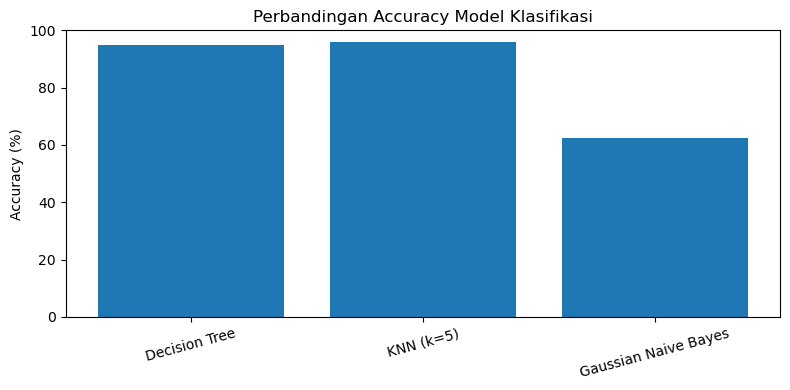

In [16]:
# Grafik perbandingan accuracy
plt.figure(figsize=(8,4))
plt.bar(results_df.index, results_df["Accuracy"] * 100)
plt.ylabel("Accuracy (%)")
plt.title("Perbandingan Accuracy Model Klasifikasi")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()
#202431124_Abhillasitta

In [18]:
# Siapkan fitur regresi dan target numerik
X_reg = data.drop(columns=["blood_glucose_level", "diabetes"])
y_reg = data["blood_glucose_level"]
# Identifikasi kolom kategorikal dan numerik
cat_reg = X_reg.select_dtypes(include="object").columns.tolist()
num_reg = X_reg.select_dtypes(exclude="object").columns.tolist()
# Preprocessing data regresi
preprocessor_reg = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ]), num_reg),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse=False
        ))
    ]), cat_reg)
])
# Membagi data latih dan data uji
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=42
)
# Membuat model regresi linear
linear_model = Pipeline([
    ("preprocessing", preprocessor_reg),
    ("model", LinearRegression())
])
# Melatih model
linear_model.fit(Xr_train, yr_train)
# Melakukan prediksi
yr_pred = linear_model.predict(Xr_test)
# Evaluasi model
regression_results = pd.DataFrame({
    "Metrik": ["R2", "MAE", "RMSE"],
    "Nilai": [
        r2_score(yr_test, yr_pred),
        mean_absolute_error(yr_test, yr_pred),
        np.sqrt(mean_squared_error(yr_test, yr_pred))
    ]
})
display(regression_results.round(4))
#202431124_Abhillasitta

,Metrik,Nilai
0,R2,0.0478
1,MAE,30.9012
2,RMSE,39.8665
